<a href="https://colab.research.google.com/github/Raj-18-45/Machine-Learning/blob/main/Supervised%20Learning/KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Diabetes Prediction Using K-Nearest Neighbors (KNN)**

Objective

To build a K-Nearest Neighbors (KNN) classification model to predict whether a person has diabetes based on medical attributes.

About the Dataset

The Pima Indians Diabetes dataset (diabetes.csv) contains 768 records and 9 columns, including medical information such as pregnancies, glucose level, blood pressure, skin thickness, insulin, BMI, diabetes pedigree function, and age.

The Outcome column is the target variable:

* 0: No diabetes
* 1: Diabetes present

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
#Step 2: Load and Explore Dataset
df=pd.read_csv('/diabetes.csv')
print(df.head())
print(df.info())
print(df.describe())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768

In [16]:
#Step 3: Handle Missing Values

cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols] = df[cols].replace(0, np.nan)

df[cols] = df[cols].fillna(df[cols].median())

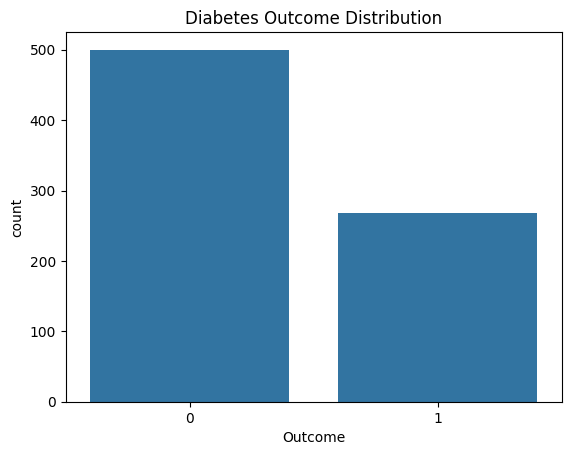

In [8]:
#Step 4: Visualize the Target Variable
sns.countplot(data=df, x='Outcome')
plt.title("Diabetes Outcome Distribution")
plt.show()

In [9]:
#Step 5: Separate Input and Output Variables
X=df.drop('Outcome',axis=1)
y=df['Outcome']

In [14]:
#Split the Dataset
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2, random_state=1
)

In [17]:
#Step 7: Normalize the Data
scaler=StandardScaler()
x_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [18]:
#Step 9: Train the Final Model
model=KNeighborsClassifier(n_neighbors=5)
model.fit(X_train,y_train)

KNeighborsClassifier()

In [20]:
#Step 9: Train the Final Model
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

Accuracy: 0.6428571428571429
Confusion Matrix:
 [[99  0]
 [55  0]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


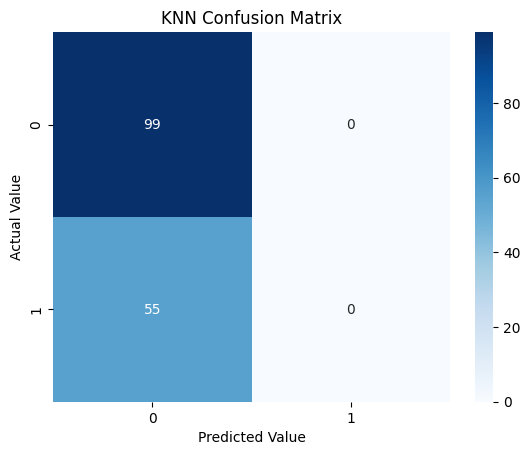

In [21]:
#Step 11: Visualize the Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")
plt.title("KNN Confusion Matrix")
plt.show()